In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
df = pd.read_csv('uber.csv')
print("Dataset head:")
print(df.head())

Dataset head:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                

In [5]:
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [6]:
# Drop rows with missing values if any
df = df.dropna()
# Feature engineering: Convert datetime to useful features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['dayofweek'] = df['pickup_datetime'].dt.dayofweek

In [9]:
df = df[(df['distance_km'] > 0.01) & (df['fare_amount'] > 0)]
print(f"\nData shape after cleaning: {df.shape}")



Data shape after cleaning: (193868, 12)


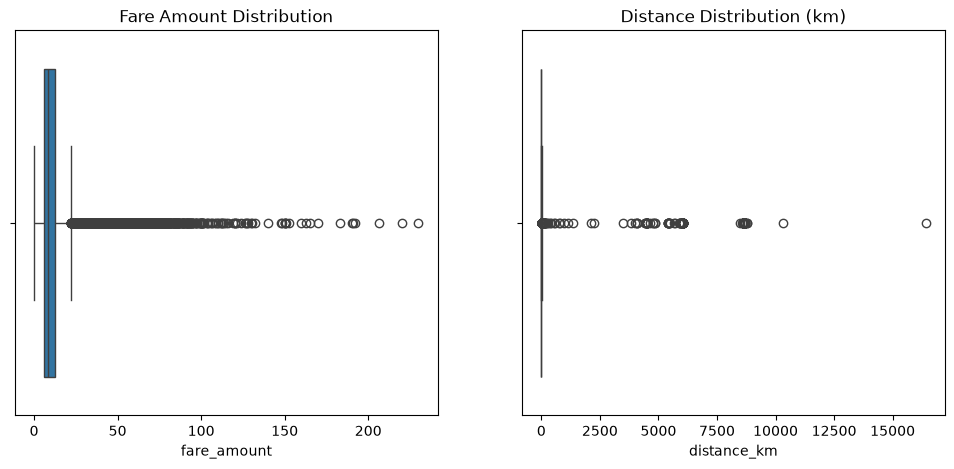


Data shape after removing outliers: (190709, 12)


In [10]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Distribution")
plt.subplot(1,2,2)
sns.boxplot(x=df['distance_km'])
plt.title("Distance Distribution (km)")
plt.show()
fare_99 = df['fare_amount'].quantile(0.99)
dist_99 = df['distance_km'].quantile(0.99)
df = df[(df['fare_amount'] <= fare_99) & (df['distance_km'] <= dist_99)]
print(f"\nData shape after removing outliers: {df.shape}")

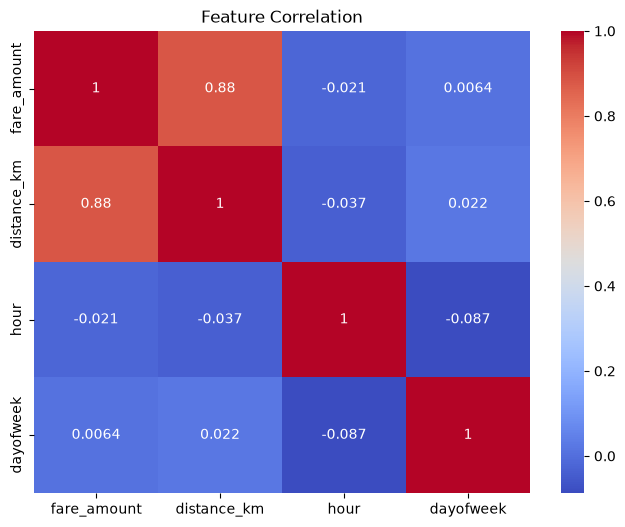

In [12]:
plt.figure(figsize=(8,6))
sns.heatmap(df[['fare_amount', 'distance_km', 'hour', 'dayofweek']].corr(),annot=True, cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

In [14]:
features = ['distance_km', 'hour', 'dayofweek']
X = df[features]
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)
# 6. Linear Regression model
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)


In [15]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [18]:
def evaluate(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{model_name} - RMSE: {rmse:.2f}, R2: {r2:.4f}")
evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_rf, "Random Forest")

Linear Regression - RMSE: 3.65, R2: 0.7715
Random Forest - RMSE: 3.77, R2: 0.7566
